En esta práctica se implementaron distintos métodos de diferenciación numérica para resolver problemas físicos. Primero, se calcularon derivadas mediante diferencias centrales y se compararon con sus soluciones analíticas. Posteriormente, se estudió el campo eléctrico generado por distribuciones de cargas, utilizando integración numérica y el gradiente del potencial eléctrico. También se calcularon derivadas parciales mediante diferencias centrales, hacia adelante y hacia atrás, para visualizar el relieve terrestre y la superficie de silicio mediante datos STM. Finalmente, se utilizó la fórmula integral de Cauchy para calcular derivadas de orden superior de una función compleja, comparando los resultados numéricos con los valores analíticos y observando los errores asociados a la precisión numérica.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math as mt

# 1. Diferenciación numérica

In [2]:
# Creamos la función de derivación central 
def DerivacionCentral(f,x,h):
    return (f(x+(h/2))-f(x-(h/2)))/h

In [3]:
# Creamos la función f(x)
def tan(x):
    return 1+ (1/2)*mt.tanh(x*2)

In [4]:
x_1 = np.linspace(-2,2,100)
y_1 = []
for i in x_1:
    y_1.append(tan(i))

y_1 = np.array(y_1)

Text(0, 0.5, 'F(x)')

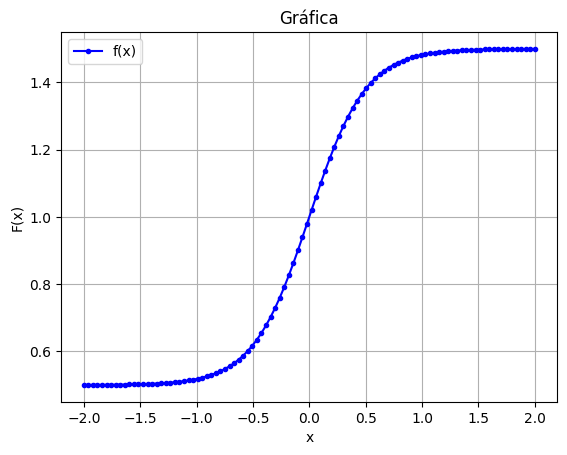

In [5]:
# Gráficamos la función 
plt.plot(x_1,y_1, color = "blue", label= "f(x)", marker = ".")
plt.grid()
plt.legend(loc = "best")
plt.title("Gráfica")
plt.xlabel("x")
plt.ylabel("F(x)")

In [6]:
y_1p = []
for i in x_1:
    y_1p.append(DerivacionCentral(tan,i,0.0005))
y_1p = np.array(y_1p)

Text(0, 0.5, 'F(x)')

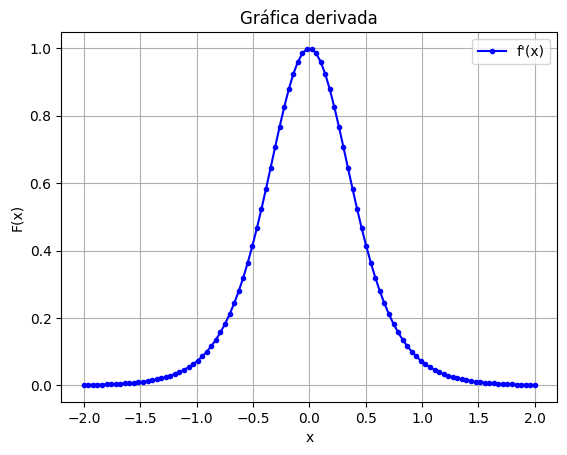

In [7]:
# Gráficamos la función derivada
plt.plot(x_1,y_1p, color = "blue", label= "f'(x)", marker = ".")
plt.grid()
plt.legend(loc = "best")
plt.title("Gráfica derivada")
plt.xlabel("x")
plt.ylabel("F(x)")

La función está definida por:

$$
f(x)=1+\frac{1}{2}\tanh(2x)
$$

Derivando respecto a $x$:

$$
f'(x)=\frac{d}{dx}\left(1+\frac{1}{2}\tanh(2x)\right)
$$

Aplicando la linealidad de la derivada:

$$
f'(x)=\frac{1}{2}\frac{d}{dx}\tanh(2x)
$$

Utilizando la regla de la cadena y la identidad

$$
\frac{d}{du}\tanh(u)=\operatorname{sech}^2(u)
$$

con $u=2x$, tenemos:

$$
f'(x)=\frac{1}{2}\operatorname{sech}^2(2x)(2)
$$

Por lo tanto, la derivada analítica es:

$$
\boxed{f'(x)=\operatorname{sech}^2(2x)
=\frac{1}{\cosh^2(2x)}}
$$


In [8]:
def derivadaTan(x):
    return mt.sinh(2*x)**2

In [9]:
y_analitica = 1 / np.cosh(2*x_1)**2

Text(0, 0.5, 'F(x)')

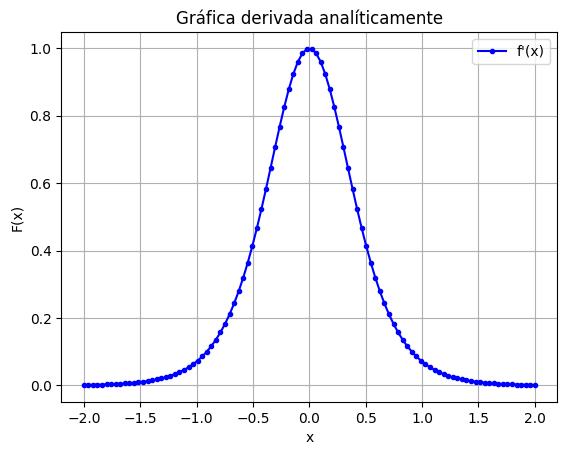

In [10]:
# Gráficamos la función derivada
plt.plot(x_1,y_analitica, color = "blue", label= "f'(x)", marker = ".")
plt.grid()
plt.legend(loc = "best")
plt.title("Gráfica derivada analíticamente")
plt.xlabel("x")
plt.ylabel("F(x)")

Text(0, 0.5, 'F(x)')

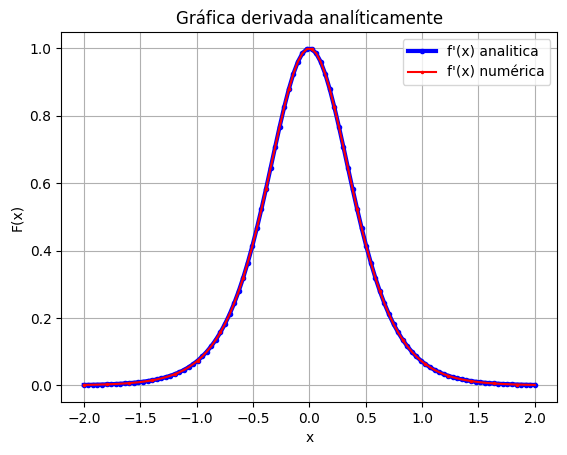

In [11]:
# Gráficamos la función derivada
plt.plot(x_1,y_analitica, color = "blue", linewidth=3, label= "f'(x) analitica", marker = ".")
plt.plot(x_1,y_1p, color = "red", markersize=3, markevery=5,  label= "f'(x) numérica", marker = ".")
plt.grid()
plt.legend(loc = "best")
plt.title("Gráfica derivada analíticamente")
plt.xlabel("x")
plt.ylabel("F(x)")

# 2. Campo eléctrico de una distribución de cargas

In [12]:
x_2 = np.linspace(-0.5, 0.5, 101)
y_2 = np.linspace(-0.5, 0.5, 101)

X, Y = np.meshgrid(x_2, y_2) # creamos la cuadrícula

In [13]:
q_1 = [-0.05,0 ]
q_2 = [0.05, 0]

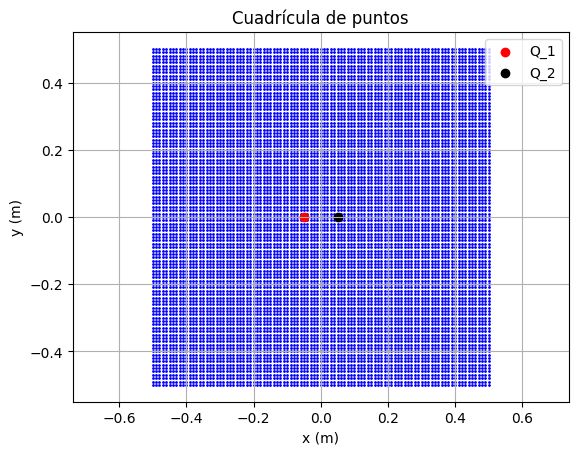

In [14]:
plt.scatter(X, Y, s=1, color="blue")
plt.scatter(q_1[0], q_1[1], color="red" ,label = "Q_1")
plt.scatter(q_2[0], q_2[1], color="black", label = "Q_2")
plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Cuadrícula de puntos")
plt.axis("equal")
plt.grid()
plt.legend(loc = "best")
plt.show()

In [15]:
epsilon_0 = 8.8541878128e-12  # F/m (SI)


In [16]:
R_1 = np.zeros((101,101)) # Creamos las distancias de la particula a cualquier punto de plano (x,y)
for i in range(101):
    for j in range(101):
        R_1[i,j]= ((q_1[0]-X[i,j])**2+(Y[i,j])**2)**(1/2)

R_2 = np.zeros((101,101))
for i in range(101):
    for j in range(101):
        R_2[i,j]= ((q_2[0]-X[i,j])**2+(Y[i,j])**2)**(1/2)

In [17]:
def potencial_1(Q_1,Q_2, r_1, r_2):
    if r_1 == 0 or r_2 == 0:
        return 0
    else:
        return (1/(4*np.pi*epsilon_0)) * (Q_1/r_1+ Q_2/r_2)

Investigando, tengo que requiere más poder computacional, y en general, cuando tenemos ese tipo de funciones, solo podemos hacer término por término, por eso, en todas mis tareas uso un ciclo for para calcular f(x), vamos a utilizar funciones más avanzadas para que la función reciba entradas de matrices. 
Para ello vamos a repasar algunas funciones que nos ayudaran 

In [18]:
np.full_like?

Signature:      
np.full_like(
    a,
    fill_value,
    dtype=None,
    order='K',
    subok=True,
    shape=None,
    *,
    device=None,
)
Call signature:  np.full_like(*args, **kwargs)
Type:            _ArrayFunctionDispatcher
String form:     <function full_like at 0x00000186BE7B5DD0>
File:            c:\users\piloto 01\anaconda3\envs\cursodemachinglearning\lib\site-packages\numpy\_core\numeric.py
Docstring:      
Return a full array with the same shape and type as a given array.

Parameters
----------
a : array_like
    The shape and data-type of `a` define these same attributes of
    the returned array.
fill_value : array_like
    Fill value.
dtype : data-type, optional
    Overrides the data type of the result.
order : {'C', 'F', 'A', or 'K'}, optional
    Overrides the memory layout of the result. 'C' means C-order,
    'F' means F-order, 'A' means 'F' if `a` is Fortran contiguous,
    'C' otherwise. 'K' means match the layout of `a` as closely
    as possible.
subok : bool,

In [19]:
np.divide?

Signature:      
np.divide(
    x1,
    x2,
    /,
    out=None,
    *,
    where=True,
    casting='same_kind',
    order='K',
    dtype=None,
    subok=True,
    signature=None,
)
Call signature:  np.divide(*args, **kwargs)
Type:            ufunc
String form:     <ufunc 'divide'>
File:            c:\users\piloto 01\anaconda3\envs\cursodemachinglearning\lib\site-packages\numpy\__init__.py
Docstring:      
divide(x1, x2, /, out=None, *, where=True, casting='same_kind', order='K', dtype=None, subok=True[, signature])

Divide arguments element-wise.

Parameters
----------
x1 : array_like
    Dividend array.
x2 : array_like
    Divisor array.
    If ``x1.shape != x2.shape``, they must be broadcastable to a common
    shape (which becomes the shape of the output).
out : ndarray, None, or tuple of ndarray and None, optional
    A location into which the result is stored. If provided, it must have
    a shape that the inputs broadcast to. If not provided or None,
    a freshly-allocated arra

In [20]:
def potencial(Q1,Q2,r1,r2):
    #Creamos un arreglo con dimención de r1, por conveniencia lo llamaremos como la salida phi
    phi =np.full_like(r1, np.nan, dtype = float)
    # Vamos a calcular la divición en q1/r1, pero teniendo cuidado de cuando pase r1 = 0 
    np.divide(Q1, r1, out = phi, where =(r1 != 0))
    # Para nuestro segundo arreglo hacemos lo mismo 
    termino_2 = np.zeros_like(r2, dtype=float)
    np.divide(Q2, r2, out=termino_2, where=(r2 != 0))

    # Sumamos los términos
    phi += termino_2
    # División entre las constantes
    phi /= 4*np.pi*epsilon_0

    return phi 

In [21]:
# Vamos probarlo 
potencial(1,-1, R_1, R_2)

array([[ 1.26942612e+09,  1.28172349e+09,  1.29357418e+09, ...,
        -1.29357418e+09, -1.28172349e+09, -1.26942612e+09],
       [ 1.30821788e+09,  1.32169845e+09,  1.33475013e+09, ...,
        -1.33475013e+09, -1.32169845e+09, -1.30821788e+09],
       [ 1.34818815e+09,  1.36293042e+09,  1.37726560e+09, ...,
        -1.37726560e+09, -1.36293042e+09, -1.34818815e+09],
       ...,
       [ 1.34818815e+09,  1.36293042e+09,  1.37726560e+09, ...,
        -1.37726560e+09, -1.36293042e+09, -1.34818815e+09],
       [ 1.30821788e+09,  1.32169845e+09,  1.33475013e+09, ...,
        -1.33475013e+09, -1.32169845e+09, -1.30821788e+09],
       [ 1.26942612e+09,  1.28172349e+09,  1.29357418e+09, ...,
        -1.29357418e+09, -1.28172349e+09, -1.26942612e+09]],
      shape=(101, 101))

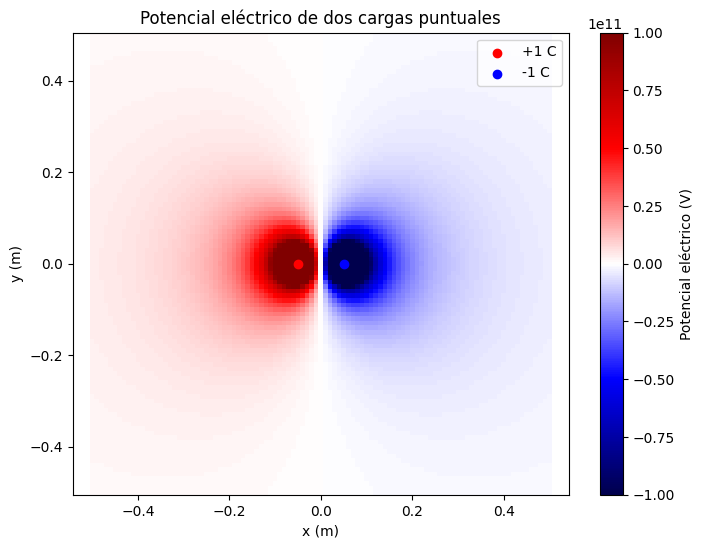

In [22]:

# Calculamos el potencial eléctrico
Phi = potencial(1, -1, R_1, R_2)

# Creamos la gráfica
plt.figure(figsize=(8, 6))

plt.pcolormesh(X, Y, Phi, cmap="seismic", shading="auto", vmin=-1e11, vmax=1e11)

# Barra de colores
plt.colorbar(label="Potencial eléctrico (V)")

# Posiciones de las cargas
plt.scatter(q_1[0], q_1[1], color="red", label="+1 C")

plt.scatter(q_2[0], q_2[1], color="blue", label="-1 C")

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Potencial eléctrico de dos cargas puntuales")
plt.axis("equal")
plt.legend()
plt.show()


## Calculo de las derivadas parciales 

In [23]:
def parcialx(f,x, y, h):
    return (f(x+h/2, y)-f(x-h/2, y))/h


In [24]:
def parcialy(f,x, y, h):
    return (f(x, y+h/2)-f(x, y-h/2))/h

In [25]:
def parcialxy(f,x, y, h):
    return (f(x+h/2, y+h/2)-f(x-h/2, y+h/2))/h -(f(x+h/2, y-h/2)+f(x-h/2, y-h/2))/h

En esta parte, tenemos que definir otra vez el potencial, ya que al tener derivadas, la función debe quedar en otros términos, para poder derivar parcialmente. 

In [26]:
np.errstate?

Init signature:
np.errstate(
    *,
    call=<numpy._core._ufunc_config._unspecified object at 0x00000186B8630D70>,
    all=None,
    divide=None,
    over=None,
    under=None,
    invalid=None,
)
Docstring:     
errstate(**kwargs)

Context manager for floating-point error handling.

Using an instance of `errstate` as a context manager allows statements in
that context to execute with a known error handling behavior. Upon entering
the context the error handling is set with `seterr` and `seterrcall`, and
upon exiting it is reset to what it was before.

..  versionchanged:: 1.17.0
    `errstate` is also usable as a function decorator, saving
    a level of indentation if an entire function is wrapped.

.. versionchanged:: 2.0
    `errstate` is now fully thread and asyncio safe, but may not be
    entered more than once.
    It is not safe to decorate async functions using ``errstate``.

Parameters
----------
kwargs : {divide, over, under, invalid}
    Keyword arguments. The valid keywor

In [27]:
def potencial_xy(x, y):
    Q_1 = 1
    Q_2 = -1

    x1, y1 = q_1
    x2, y2 = q_2

    r1 = np.sqrt((x-x1)**2 + (y-y1)**2)
    r2 = np.sqrt((x-x2)**2 + (y-y2)**2)

    with np.errstate(divide="ignore", invalid="ignore"):
        phi = (1/(4*np.pi*epsilon_0)) * (Q_1/r1 + Q_2/r2)

    return np.where((r1 == 0) | (r2 == 0), np.nan, phi)

In [28]:
Phi = potencial_xy(X, Y)
Phi.shape

(101, 101)

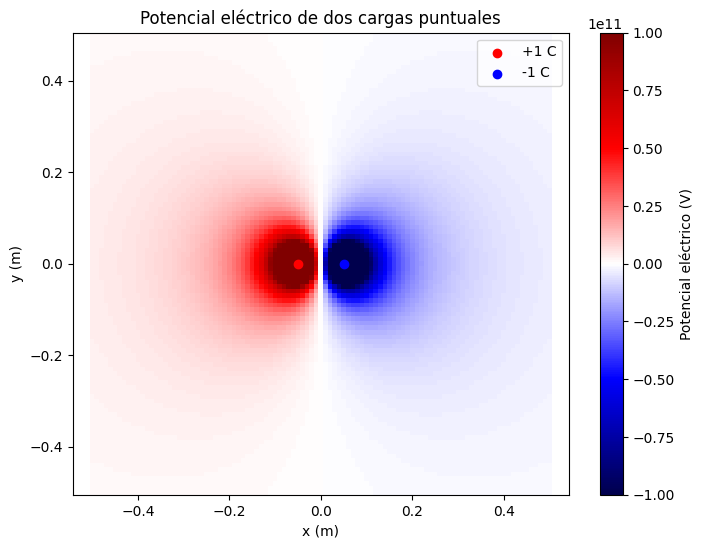

In [29]:

# Calculamos el potencial eléctrico
Phi = potencial_xy(X, Y)

# Creamos la gráfica
plt.figure(figsize=(8, 6))

plt.pcolormesh(X, Y, Phi, cmap="seismic", shading="auto", vmin=-1e11, vmax=1e11)

# Barra de colores
plt.colorbar(label="Potencial eléctrico (V)")

# Posiciones de las cargas
plt.scatter(q_1[0], q_1[1], color="red", label="+1 C")

plt.scatter(q_2[0], q_2[1], color="blue", label="-1 C")

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Potencial eléctrico de dos cargas puntuales")
plt.axis("equal")
plt.legend()
plt.show()


In [30]:
Ex = -parcialx(potencial_xy, X, Y, 0.01)
Ey = -parcialy(potencial_xy, X, Y, 0.01)

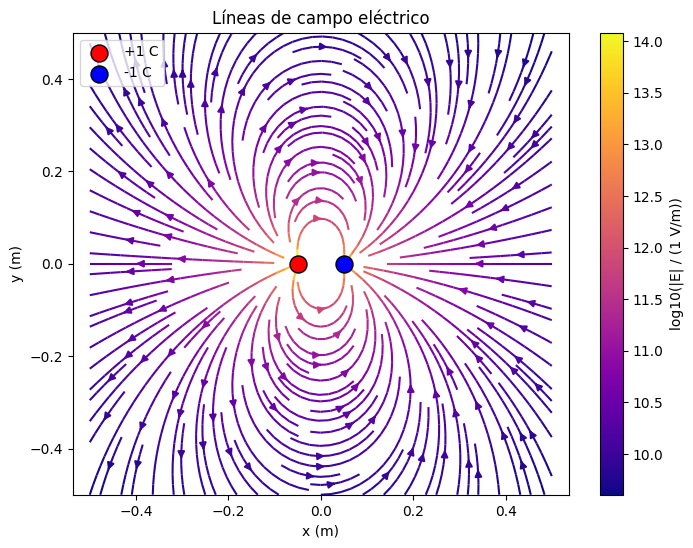

In [31]:

# Magnitud del campo eléctrico
E = np.sqrt(Ex**2 + Ey**2)

# Normalizamos las componentes para visualizar la dirección
Ex_norm = np.divide(Ex, E, out=np.zeros_like(Ex), where=(E != 0) & np.isfinite(E))
Ey_norm = np.divide(Ey, E, out=np.zeros_like(Ey), where=(E != 0) & np.isfinite(E))

# Creamos la gráfica
plt.figure(figsize=(8, 6))

plt.streamplot(x_2, y_2, Ex_norm, Ey_norm, color=np.log10(np.maximum(E, 1)), cmap="plasma", density=1.5)

plt.colorbar(label="log10(|E| / (1 V/m))")

# Posiciones de las cargas
plt.scatter(q_1[0], q_1[1], color="red", s=150, edgecolors="black", zorder=5, label="+1 C")

plt.scatter(q_2[0], q_2[1], color="blue", s=150, edgecolors="black", zorder=5, label="-1 C")

plt.xlabel("x (m)")
plt.ylabel("y (m)")
plt.title("Líneas de campo eléctrico")
plt.axis("equal")
plt.legend()
plt.show()


In [32]:
# Importamos la libreria para obtener los polinomios de legengre
from numpy.polynomial.legendre import Legendre

# Vamos a construir los w_k 
def w_k_f(N, a, b):
    w_k_array = []
    P = Legendre.basis(N)
    x = P.roots()
    for i in range(N):
        w_k = ((b-a)/2)*(2/ (1-x[i]**2)) * (P.deriv()(x[i]))**(-2)
        w_k_array.append(w_k)
    w_k_array = np.array(w_k_array)
    return w_k_array

def integralGauss_Legendre_doble(f, N, a, b, c, d):
    integral_v_doble = 0

    P = Legendre.basis(N)
    x_k = P.roots()

    pesos_1 = w_k_f(N, a, b)
    pesos_2 = w_k_f(N, c, d)

    for k in range(N):
        x_p = ((b-a)/2)*x_k[k] + (b+a)/2

        for j in range(N):
            y_p = ((d-c)/2)*x_k[j] + (d+c)/2

            integral_v_doble += pesos_1[k]*pesos_2[j]*f(x_p, y_p)

    return integral_v_doble

In [33]:

# Constantes
epsilon_0 = 8.8541878128e-12
q_0 = 100       # C/m²
L = 0.10        # m
delta = 0.0025  # m, parámetro de regularización

# Densidad superficial de carga
def sigma(x_p, y_p):
    return q_0*np.sin(2*np.pi*x_p/L)*np.sin(2*np.pi*y_p/L)


In [34]:
# Potencial eléctrico mediante integración doble
def potencial_continuo(x, y, N=20):

    def integrando(x_p, y_p):
        R = np.sqrt((x-x_p)**2 + (y-y_p)**2 + delta**2)
        return sigma(x_p, y_p)/R

    integral = integralGauss_Legendre_doble(integrando, N, -L/2, L/2, -L/2, L/2)

    return integral/(4*np.pi*epsilon_0)

In [35]:

# Cuadrícula de observación
x_3 = np.linspace(-0.5, 0.5, 101)
y_3 = np.linspace(-0.5, 0.5, 101)

X_3, Y_3 = np.meshgrid(x_3, y_3)

# Matriz del potencial eléctrico
Phi_3 = np.zeros_like(X_3)

for i in range(101):
    for j in range(101):
        Phi_3[i,j] = potencial_continuo(X_3[i,j], Y_3[i,j])


In [36]:

h = 0.01  # Separación entre puntos, en metros

dPhi_dy, dPhi_dx = np.gradient(Phi_3, h, h)

Ex_3 = -dPhi_dx
Ey_3 = -dPhi_dy

# Magnitud del campo eléctrico
E_3 = np.sqrt(Ex_3**2 + Ey_3**2)


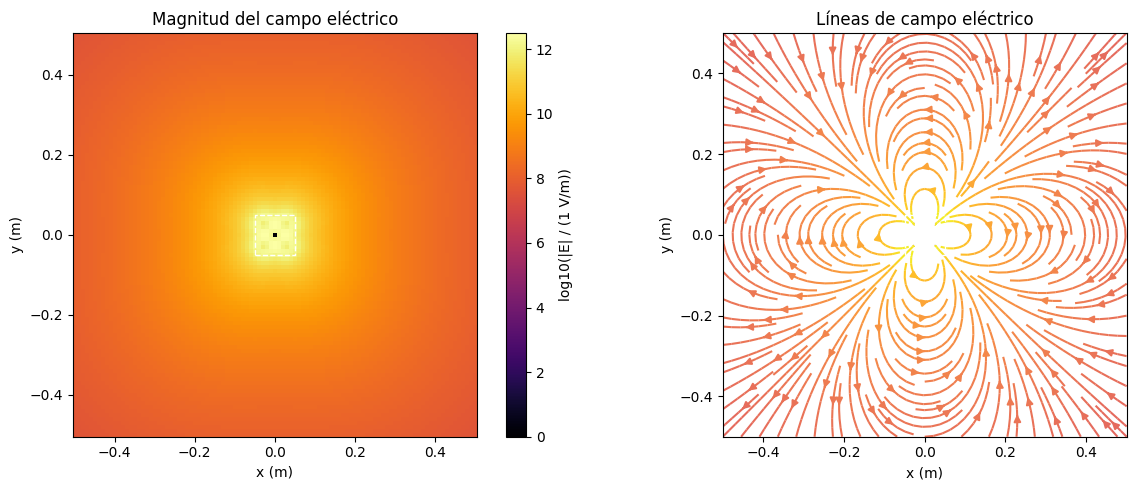

In [37]:

fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Magnitud del campo eléctrico
im = ax[0].pcolormesh(X_3, Y_3, np.log10(np.maximum(E_3, 1)),cmap="inferno", shading="auto")

fig.colorbar(im, ax=ax[0], label="log10(|E| / (1 V/m))")

ax[0].set_title("Magnitud del campo eléctrico")

# Líneas de campo eléctrico
ax[1].streamplot(x_3, y_3, Ex_3, Ey_3,color=np.log10(np.maximum(E_3, 1)),cmap="plasma", density=1.5)

ax[1].set_title("Líneas de campo eléctrico")

# Representar el cuadrado cargado
for a in ax:
    a.plot(
        [-L/2, L/2, L/2, -L/2, -L/2],
        [-L/2, -L/2, L/2, L/2, -L/2],
        "w--", linewidth=1
    )
    a.set_xlabel("x (m)")
    a.set_ylabel("y (m)")
    a.set_aspect("equal")

plt.tight_layout()
plt.show()


# 3- Procesamiento de im ́agenes y STM

## a) Leer archivo, calculo de las derivadas parciales 

### Leer el archivo 

In [38]:
entrada = open("data/altitudes.txt", "r")

datos = []

for linea in entrada:
    palabras = linea.split()
    palabras = list(map(float, palabras))
    datos.append(palabras)

datos = np.array(datos)

print(datos.shape)


(512, 1024)


In [39]:
# Vamos a utilizar la función de numpy para leer esos archivos y ya no el código que utilizamos en las tareas anteriores porque está más optimizado
w = np.loadtxt("data/altitudes.txt")
print(w.shape)

(512, 1024)


### Calculo de las derivadas parciales 

In [40]:
#Creamos la cuadricúla que vamos a llenar con los valores de las derivadas parciales. 
h = 30000
derivadax = np.zeros((512,1024))
derivaday = np.zeros((512,1024))

In [41]:
# Derivada parcial respecto a x
for i in range(0, 512):
    for j in range(1, 1023):
        derivadax[i,j] = (w[i,j+1] - w[i,j-1])/(2*h)

In [42]:
# Derivada parcial respecto a y
for i in range(1, 511):
    for j in range(0, 1024):
        derivaday[i,j] = (w[i+1,j] - w[i-1,j])/(2*h)

Calculo de la derviada en los extremos en x

In [43]:
# Verificamos los extremos en x
print("Primer extremo en x:")
print(derivadax[:,0])

print("Último extremo en x:")
print(derivadax[:,-1])

Primer extremo en x:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.

In [44]:
derivadax[:,0] = (w[:,1]-w[:,0])/h
derivadax[:,-1] = (w[:, -1]-w[:,-2])/h

In [45]:
#Verificamos los extremos en x
print("Primer extremo en x:")
print(derivadax[:,0])

print("Último extremo en x:")
print(derivadax[:,-1])

Primer extremo en x:
[ 4.26666667e-05  3.37666667e-04  1.63333333e-04 -7.42666667e-04
 -6.46333333e-04  1.49333333e-04  3.76666667e-05 -1.06666667e-05
 -5.16333333e-04 -2.93333333e-05 -9.20000000e-05  3.42333333e-04
  7.88333333e-04  1.09166667e-03  9.89666667e-04  7.32000000e-04
 -1.78433333e-03  9.80000000e-05 -3.12000000e-04  5.37000000e-04
  5.99666667e-04 -2.72000000e-04 -1.55466667e-03  1.75133333e-03
  8.10666667e-04 -5.40966667e-03 -6.17166667e-03  1.89100000e-03
  4.27100000e-03 -1.99000000e-03 -2.24066667e-03  1.33733333e-03
  9.83333333e-05 -5.82666667e-04 -2.14033333e-03  6.23666667e-04
 -1.51500000e-03 -4.45333333e-04  1.54766667e-03  3.32333333e-04
 -3.09333333e-04 -6.52633333e-04 -7.87666667e-05 -2.44200000e-04
 -2.58766667e-04 -1.17433333e-04 -5.51100000e-05 -9.66733333e-05
 -8.18900000e-05 -5.45233333e-05 -2.85533333e-05  6.60333333e-06
  1.42084667e-04  1.44736667e-03  1.01657867e-03  8.37333333e-06
 -1.08210000e-04  5.82500000e-05 -3.25633333e-05 -2.85643333e-04
 -4.

Calculo de la derivada en y 

In [46]:
# Verificamos en el eje de las y 

print("Primer extremo en y:")
print(derivaday[0,:])

print("Último extremo en y:")
print(derivaday[-1,:])

Primer extremo en y:
[0. 0. 0. ... 0. 0. 0.]
Último extremo en y:
[0. 0. 0. ... 0. 0. 0.]


In [47]:
derivaday[0,:] = (w[1,:]-w[0,:])/h
derivaday[-1,:] = (w[-1,:]-w[-2,:])/h

In [48]:
# Verificamos en el eje de las y 

print("Primer extremo en y:")
print(derivaday[0,:])

print("Último extremo en y:")
print(derivaday[-1,:])

Primer extremo en y:
[0.004891   0.005186   0.00547167 ... 0.00385367 0.00422067 0.00458067]
Último extremo en y:
[-0.003727   -0.003699   -0.003672   ... -0.00382    -0.00378833
 -0.00375833]


In [49]:
derivadax

array([[ 4.26666667e-05,  3.65000000e-05,  2.91666667e-05, ...,
         9.03333333e-05,  8.10000000e-05,  7.56666667e-05],
       [ 3.37666667e-04,  3.26833333e-04,  3.04333333e-04, ...,
         4.61000000e-04,  4.44500000e-04,  4.35666667e-04],
       [ 1.63333333e-04,  6.65000000e-05, -7.51666667e-05, ...,
         9.66500000e-04,  8.85166667e-04,  8.15333333e-04],
       ...,
       [-5.33333333e-05, -5.48333333e-05, -5.55000000e-05, ...,
        -5.00000000e-05, -5.35000000e-05, -5.73333333e-05],
       [-3.10000000e-05, -3.03333333e-05, -3.25000000e-05, ...,
        -3.28333333e-05, -3.38333333e-05, -3.43333333e-05],
       [-3.00000000e-06, -2.83333333e-06, -2.16666667e-06, ...,
        -1.66666667e-06, -3.00000000e-06, -4.33333333e-06]],
      shape=(512, 1024))

In [50]:
derivaday

array([[ 0.004891  ,  0.005186  ,  0.00547167, ...,  0.00385367,
         0.00422067,  0.00458067],
       [ 0.02438683,  0.02444717,  0.02441683, ...,  0.02337717,
         0.0238115 ,  0.02418133],
       [ 0.03476033,  0.03422017,  0.033555  , ...,  0.03458617,
         0.03478583,  0.03493867],
       ...,
       [-0.00280683, -0.00280083, -0.00279533, ..., -0.00281483,
        -0.00281233, -0.00281033],
       [-0.00326417, -0.003239  , -0.00321217, ..., -0.00334017,
        -0.00331617, -0.00328967],
       [-0.003727  , -0.003699  , -0.003672  , ..., -0.00382   ,
        -0.00378833, -0.00375833]], shape=(512, 1024))

## b) Intensidad 

In [ ]:
# Ángulo en grados
phi_1 = 45

# Convertir a radianes 
radianes = mt.radians(phi_1)


0.7853981633974483

In [75]:
def intensidad(dx,dy, phi):
    phi = mt.radians(phi)
    return (np.cos(phi) * dx + np.sin(phi) * dy)/ (np.sqrt((dx)**2)+(dy)**2+1)

In [78]:
I = intensidad(derivadax, derivaday, 45)

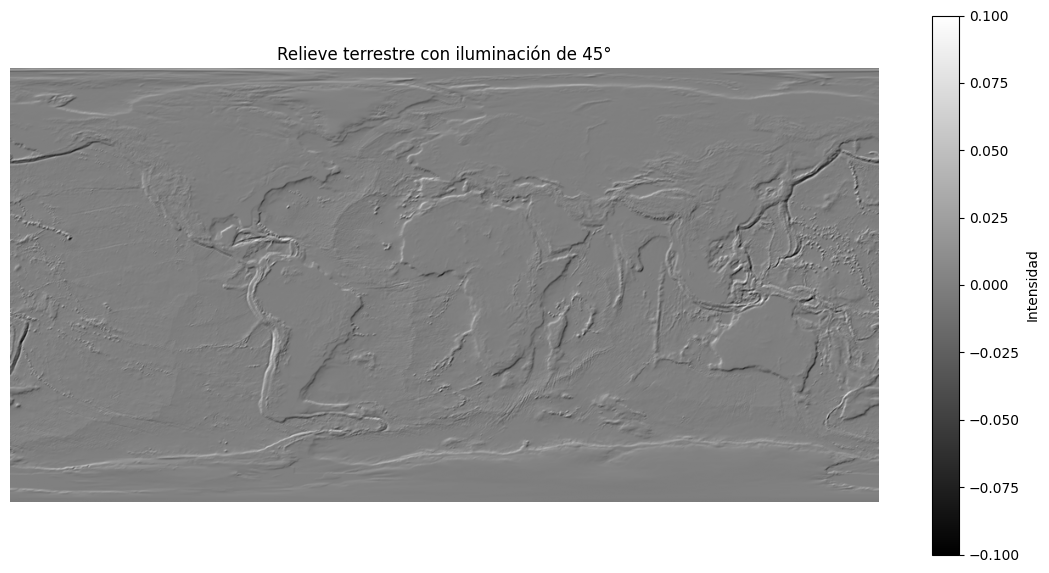

In [80]:
plt.figure(figsize=(14, 7))
plt.imshow(I, cmap="gray", vmin=-0.1, vmax=0.1)
plt.colorbar(label="Intensidad")
plt.title("Relieve terrestre con iluminación de 45°")
plt.axis("off")
plt.show()

## STM

In [82]:
stm = np.loadtxt("data/stm.txt")
h = 2.5
print(stm.shape)

(663, 676)


In [86]:
derivadax_1 = np.zeros(stm.shape)
derivaday_1 = np.zeros(stm.shape)

In [87]:
# Derivada parcial respecto a x
for i in range(0, 663):
    for j in range(1, 675):
        derivadax_1[i,j] = (stm[i,j+1] - stm[i,j-1])/(2*h)

In [89]:
# Derivada parcial respecto a y
for i in range(1, 662):
    for j in range(0, 676):
        derivaday_1[i,j] = (stm[i+1,j] - stm[i-1,j])/(2*h)

In [92]:
# Verificamos los extremos en x
#print("Primer extremo en x:")
#print(derivadax_1[:,0])

#print("Último extremo en x:")
#print(derivadax_1[:,-1])

derivadax_1[:,0] = (stm[:,1]-stm[:,0])/h
derivadax_1[:,-1] = (stm[:, -1]-stm[:,-2])/h

In [96]:
derivaday_1[0,:] = (stm[1,:]-stm[0,:])/h
derivaday_1[-1,:] = (stm[-1,:]-stm[-2,:])/h

In [ ]:
I_1 = intensidad(derivadax_1, derivaday_1, 45)

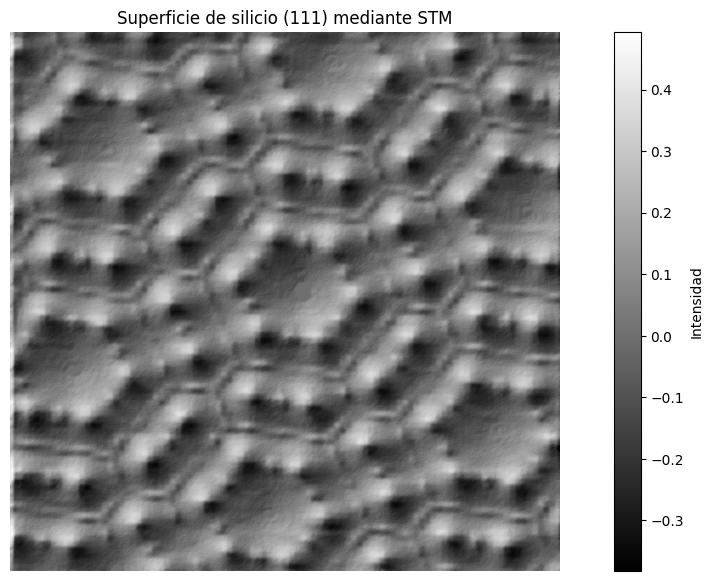

In [102]:
plt.figure(figsize=(14, 7))
plt.imshow(I_1, cmap="gray", vmin=I_1.min(), vmax=I_1.max())
plt.colorbar(label="Intensidad")
plt.title("Superficie de silicio (111) mediante STM")
plt.axis("off")
plt.show()

# Derivación mediante integración.

In [104]:
import cmath as cmt

In [113]:
def derivada_compleja(f,N,m):
    dericom = 0
    for k in range(0,N):
        dericom += f(cmt.exp(1j*np.pi*k*2/N))* cmt.exp(-1j*np.pi*k*2*m/N)
    return mt.factorial(m)/N * dericom


In [114]:
def f(z):
    return cmt.exp(2*z)

In [118]:
for i in range(0, 21):
    print(derivada_compleja(f, 10000, i))

(1.000000000000002+2.416178368491728e-16j)
(1.9999999999999925-8.098348380780608e-17j)
(3.99999999999999+8.162047426818475e-17j)
(8.000000000000002-1.2622434347742128e-15j)
(16.000000000000018+1.9462972900008423e-15j)
(32.00000000000003-2.2116891651435822e-14j)
(64.00000000000026-1.9221524372170505e-13j)
(128.00000000000168-7.52842788109831e-13j)
(255.99999999998894-4.364089090103107e-12j)
(511.9999999999226+3.841439166762939e-12j)
(1024.000000000611+2.917187291728851e-10j)
(2048.0000000048944+9.003738155044515e-09j)
(4095.999999709018-2.8881649871692618e-08j)
(8191.999997537425-1.5720511861871955e-06j)
(16383.99996578755+2.1102061141675675e-05j)
(32767.999499965485-0.00044065342949579646j)
(65535.99560571488+0.0005297655390847922j)
(131071.9378405642-0.10194442758703416j)
(262142.83101705124-1.9708792001622557j)
(524273.9928697285-52.09592446412324j)
(1048190.6025824934+595.1794140887341j)
